# Appendix B | Linear Regression Model

---

# Imports

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, StandardScaler

from utils.read_csv_to_df import read_csv_to_df

# Defaults

In [2]:
SEED = 42
np.random.seed(SEED)

plt.rcParams['figure.figsize'] = (6.4, 4.8)
TARGET = 'Life Ladder'

# Fetch Data

Only the training set is used here. The test set is held back so it plays no part in choosing the model.

In [3]:
train_path = '/Q1_OLD/DATA/happiness_data_train.csv'
train_df = read_csv_to_df(path=train_path)

X = train_df.drop(columns=TARGET)
y = train_df[TARGET]

print(f'X: {X.shape[0]} rows x {X.shape[1]} features, y: {TARGET}')

X: 1559 rows x 8 features, y: Life Ladder


# Preprocessing

Follows the special treatment table in QB.3:
- **Median impute** every feature (most are skewed, and dropping incomplete rows would lose 12% of the data).
- **Yeo-Johnson** on the four skewed features (Corruption, Social support, Generosity, Negative affect). `PowerTransformer` also standardizes its output.
- **Standardize** the other four features. SGD and the penalty terms both need features on the same scale.

Everything sits inside a `Pipeline`, so in cross-validation the imputer, transformer and scaler are refit on each training fold only and the validation fold never leaks into them.

In [4]:
SKEWED_FEATURES = ['Perceptions of corruption', 'Social support', 'Generosity', 'Negative affect']
OTHER_FEATURES = [f for f in X.columns if f not in SKEWED_FEATURES]


def low_corruption_flag(corruption):
	"""Return 1.0 where Perceptions of corruption is below 0.5 (QB Callout 2), else 0.0."""
	return (corruption < 0.5).astype(float)


def make_preprocessor(add_corruption_flag=False):
	"""Build the imputing / transforming / scaling step shared by every model."""
	transformers = [
		('skewed', make_pipeline(SimpleImputer(strategy='median'), PowerTransformer(method='yeo-johnson')), SKEWED_FEATURES),
		('other', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), OTHER_FEATURES),
	]
	if add_corruption_flag:
		transformers.append((
			'flag',
			make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(low_corruption_flag, feature_names_out='one-to-one'), StandardScaler()),
			['Perceptions of corruption'],
		))
	return ColumnTransformer(transformers, verbose_feature_names_out=False)

# Cross-Validation & Evaluation Metric

- **4-fold cross-validation**, shuffled with a fixed seed so every model sees the exact same folds.
- **Main metric: RMSE** (root mean squared error). It is in the same units as Life Ladder (0 to 10 scale), so "RMSE = 0.53" reads as "predictions are typically about half a point off". It is also the square root of the loss that both the Normal Equation and SGD minimize (squared error), and it punishes large misses more than small ones.
- **Supporting metrics:** R² (share of the variance in happiness explained) and MAE (average absolute miss, less sensitive to a few big errors).
- Each table reports the mean over the 4 validation folds, the standard deviation across folds, and the mean training RMSE, so the gap between training and validation shows over or underfitting.

In [5]:
cv = KFold(n_splits=4, shuffle=True, random_state=SEED)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

results = []  # one row per model, filled by evaluate()
models = {}  # name -> unfitted pipeline, so the selected model can be rebuilt later


def evaluate(name, regressor, add_corruption_flag=False, **params):
	"""Cross-validate preprocessing + regressor on the training set and record the scores.

	Extra keyword arguments are stored in the results table as hyperparameter columns.
	"""
	pipeline = Pipeline([
		('pre', make_preprocessor(add_corruption_flag)),
		('model', regressor)
	])
	scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, return_train_score=True)

	row = {
		'model': name,
		**params,
		'train RMSE': -scores['train_rmse'].mean(),
		'val RMSE': -scores['test_rmse'].mean(),
		'val RMSE std': scores['test_rmse'].std(),
		'val MAE': -scores['test_mae'].mean(),
		'val R2': scores['test_r2'].mean(),
	}
	results.append(row)
	models[name] = pipeline
	return row


def results_table(names):
	"""Return the results rows for the given model names as a rounded DataFrame."""
	table = pd.DataFrame([r for r in results if r['model'] in names]).set_index('model')
	return table.dropna(axis=1, how='all').round(4)

# QD.1 Closed-Form Solution

The **Normal Equation** solves for the weights that minimize squared error in one step, with no learning rate or epochs:

$$\hat{\theta} = (X^T X)^{-1} X^T y$$

where $X$ has a leading column of 1s for the intercept. It is implemented by hand below as a small scikit-learn estimator so it can go through the same pipeline and cross-validation as every other model.

For comparison, scikit-learn's `LinearRegression` solves the same problem with `scipy.linalg.lstsq`, which uses the **SVD** (it never forms the inverse, so it is more numerically stable when features are highly correlated).

In [6]:
class NormalEquationRegressor(RegressorMixin, BaseEstimator):
	"""Ordinary least squares solved with the Normal Equation."""

	def fit(self, X, y):
		X_b = np.c_[np.ones(len(X)), X]  # add the intercept column
		theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ np.asarray(y)
		self.intercept_, self.coef_ = theta[0], theta[1:]
		return self

	def predict(self, X):
		return self.intercept_ + np.asarray(X) @ self.coef_

In [7]:
evaluate('Normal Equation', NormalEquationRegressor(), method='closed form')
evaluate('LinearRegression (SVD)', LinearRegression(), method='closed form')

results_table(['Normal Equation', 'LinearRegression (SVD)'])

,method,train RMSE,val RMSE,val RMSE std,val MAE,val R2
model,,,,,,
Normal Equation,closed form,0.5316,0.5343,0.0307,0.4151,0.7675
LinearRegression (SVD),closed form,0.5316,0.5343,0.0307,0.4151,0.7675


Both closed-form solvers should land on the same weights. Fit each on the full training set and compare:

In [8]:
closed_form_coefs = {}
for name in ['Normal Equation', 'LinearRegression (SVD)']:
	fitted = clone(models[name]).fit(X, y)
	closed_form_coefs[name] = pd.Series(
		[fitted['model'].intercept_, *fitted['model'].coef_],
		index=['(intercept)', *fitted['pre'].get_feature_names_out()],
	)

closed_form_coefs = pd.DataFrame(closed_form_coefs)
print(f"Largest difference between the two solvers: {closed_form_coefs.diff(axis=1).iloc[:, 1].abs().max():.2e}")
closed_form_coefs.round(4)

Largest difference between the two solvers: 2.58e-15


,Normal Equation,LinearRegression (SVD)
(intercept),5.4693,5.4693
Perceptions of corruption,-0.0958,-0.0958
Social support,0.2755,0.2755
Generosity,0.0827,0.0827
Negative affect,0.0147,0.0147
Log GDP per capita,0.3779,0.3779
Healthy life expectancy at birth,0.2356,0.2356
Freedom to make life choices,0.0447,0.0447
Positive affect,0.2117,0.2117


### Does the "Corruption < 0.5" flag help?

QB Callout 2 suggested a binary low corruption flag so a linear model can capture Corruption's L shape. Quick check with the Normal Equation:

In [9]:
evaluate('Normal Equation + corruption flag', NormalEquationRegressor(), add_corruption_flag=True, method='closed form')

results_table(['Normal Equation', 'Normal Equation + corruption flag'])

,method,train RMSE,val RMSE,val RMSE std,val MAE,val R2
model,,,,,,
Normal Equation,closed form,0.5316,0.5343,0.0307,0.4151,0.7675
Normal Equation + corruption flag,closed form,0.5315,0.5345,0.0307,0.4152,0.7673


#### Notes / Observations
- **The two closed-form solvers agree exactly:** the Normal Equation and the SVD based `LinearRegression` produce the same weights (largest difference 2.6e-15, which is floating point rounding) and the same scores.
- **Validation RMSE = 0.534 ± 0.031** (R² = 0.767, MAE = 0.415). Predictions are typically about half a point off on the 0 to 10 Life Ladder scale, and the model explains about 77% of the variance in happiness, up from 62% for GDP alone (QC.1).
- **Training RMSE (0.532) is almost identical to validation RMSE (0.534).** A gap that small means the model is not overfitting. With only 8 features and about 1,170 training rows per fold, a linear model has too few weights to memorize noise. Any remaining error comes from what a straight line cannot capture (bias), not from variance.
- **Largest weights** (on standardized features): Log GDP (0.38), Social support (0.28), Life expectancy (0.24) and Positive affect (0.21). Negative affect is close to 0 (0.015) once the other features are in the model.
- **The corruption flag adds nothing** (0.5345 vs 0.5343). The Yeo-Johnson transform already stretches out the low corruption tail, so the flag carries no new information. It is left out of every model below.

# QD.2 Stochastic Gradient Descent (SGD)

`SGDRegressor` reaches the same squared error minimum iteratively: it shuffles the rows, then nudges the weights after every single row by a step of size *learning rate* x *gradient*. One full pass over the training set is one **epoch**.

Default settings, no penalty (`penalty=None`) so it is directly comparable to the closed form. `random_state=SEED` fixes the shuffle order, so the run is reproducible.

In [10]:
evaluate('SGD (no penalty)', SGDRegressor(penalty=None, random_state=SEED), method='SGD', penalty='none')

results_table(['Normal Equation', 'LinearRegression (SVD)', 'SGD (no penalty)'])

,method,train RMSE,val RMSE,val RMSE std,val MAE,val R2,penalty
model,,,,,,,
Normal Equation,closed form,0.5316,0.5343,0.0307,0.4151,0.7675,NaN
LinearRegression (SVD),closed form,0.5316,0.5343,0.0307,0.4151,0.7675,NaN
SGD (no penalty),SGD,0.5318,0.5342,0.0307,0.4153,0.7675,none


In [11]:
sgd_fitted = clone(models['SGD (no penalty)']).fit(X, y)

pd.DataFrame({
	'Normal Equation': closed_form_coefs['Normal Equation'],
	'SGD (no penalty)': [sgd_fitted['model'].intercept_[0], *sgd_fitted['model'].coef_],
}).assign(difference=lambda d: d['SGD (no penalty)'] - d['Normal Equation']).round(4)

,Normal Equation,SGD (no penalty),difference
(intercept),5.4693,5.4744,0.0051
Perceptions of corruption,-0.0958,-0.0929,0.0030
Social support,0.2755,0.2763,0.0008
Generosity,0.0827,0.0823,-0.0004
Negative affect,0.0147,0.0132,-0.0015
Log GDP per capita,0.3779,0.3781,0.0002
Healthy life expectancy at birth,0.2356,0.2355,-0.0000
Freedom to make life choices,0.0447,0.0499,0.0053
Positive affect,0.2117,0.2154,0.0037


In [12]:
print(f"SGD stopped after {sgd_fitted['model'].n_iter_} epochs (tol = {sgd_fitted['model'].tol}: stops once the loss improves by less than this for 5 epochs in a row)")

SGD stopped after 8 epochs (tol = 0.001: stops once the loss improves by less than this for 5 epochs in a row)


#### Notes / Observations
- **SGD matches the closed form:** validation RMSE 0.5342 vs 0.5343, with every weight within 0.006 of the Normal Equation's. SGD only approximates the exact minimum because it updates on one row at a time, but on standardized features it gets close within **8 epochs**.
- The small weight differences make no practical difference to the predictions (validation R² is 0.7675 for both).
- **When to prefer which:** with 8 features and 1,559 rows the Normal Equation is instant and exact, so it is the better tool for this dataset. SGD earns its place when the data is too large to fit in memory, or when there are so many features that inverting $X^T X$ becomes slow (its cost grows with the cube of the feature count). SGD also lets the penalties below be swapped in with one argument.

# QD.3 Regularization with SGD: Ridge, Lasso and Elastic Net

Regularization adds a penalty on the size of the weights to the loss, trading a little training fit for simpler, more stable weights. The penalty strength is `alpha`:

| Model | `penalty` | Penalty term added to the loss | Effect on weights |
|---|---|---|---|
| **Ridge** | `l2` | $\alpha \sum \theta_j^2$ | Shrinks all weights toward 0, rarely exactly 0 |
| **Lasso** | `l1` | $\alpha \sum \lvert\theta_j\rvert$ | Shrinks weights and sets the weakest to exactly 0 (feature selection) |
| **Elastic Net** | `elasticnet` | mix of both, set by `l1_ratio` | In between; `l1_ratio = 0.5` here |

Three penalty values spanning three orders of magnitude: **0.001** (weak), **0.1** (moderate) and **1.0** (strong). The intercept is never penalized. Learning rate settings stay at the defaults here and are explored in QD.4.

In [13]:
ALPHAS = [0.001, 0.1, 1.0]
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}

regularized_names = []
for label, penalty in PENALTIES.items():
	for alpha in ALPHAS:
		name = f'{label} (alpha={alpha})'
		evaluate(name, SGDRegressor(penalty=penalty, alpha=alpha, l1_ratio=0.5, random_state=SEED),
				 method='SGD', penalty=penalty, alpha=alpha, l1_ratio=0.5 if penalty == 'elasticnet' else np.nan)
		regularized_names.append(name)

results_table(['SGD (no penalty)', *regularized_names])

,method,penalty,train RMSE,val RMSE,val RMSE std,val MAE,val R2,alpha,l1_ratio
model,,,,,,,,,
SGD (no penalty),SGD,none,0.5318,0.5342,0.0307,0.4153,0.7675,NaN,NaN
Ridge (alpha=0.001),SGD,l2,0.5318,0.5342,0.0307,0.4153,0.7675,0.001,NaN
Ridge (alpha=0.1),SGD,l2,0.5334,0.5356,0.0300,0.4167,0.7664,0.100,NaN
Ridge (alpha=1.0),SGD,l2,0.5822,0.5839,0.0252,0.4623,0.7229,1.000,NaN
Lasso (alpha=0.001),SGD,l1,0.5318,0.5342,0.0307,0.4153,0.7675,0.001,NaN
Lasso (alpha=0.1),SGD,l1,0.5503,0.5531,0.0284,0.4353,0.7510,0.100,NaN
Lasso (alpha=1.0),SGD,l1,1.1126,1.1147,0.0147,0.9224,-0.0091,1.000,NaN
Elastic Net (alpha=0.001),SGD,elasticnet,0.5318,0.5342,0.0307,0.4153,0.7675,0.001,0.5
Elastic Net (alpha=0.1),SGD,elasticnet,0.5382,0.5407,0.0305,0.4228,0.7619,0.100,0.5


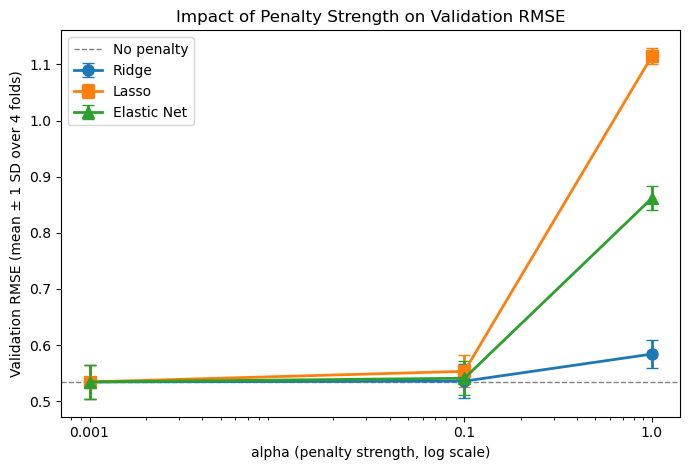

In [14]:
reg_table = pd.DataFrame([r for r in results if r['model'] in regularized_names])
baseline_rmse = next(r['val RMSE'] for r in results if r['model'] == 'SGD (no penalty)')

fig, ax = plt.subplots(figsize=(7, 4.8))
for (label, penalty), marker in zip(PENALTIES.items(), ['o', 's', '^']):
	rows = reg_table[reg_table['penalty'] == penalty]
	ax.errorbar(rows['alpha'], rows['val RMSE'], yerr=rows['val RMSE std'], marker=marker, markersize=8, lw=2, capsize=4, label=label)
ax.axhline(baseline_rmse, color='gray', ls='--', lw=1, label='No penalty')
ax.set_xscale('log')
ax.set_xticks(ALPHAS, labels=[str(a) for a in ALPHAS])
ax.set_xlabel('alpha (penalty strength, log scale)')
ax.set_ylabel('Validation RMSE (mean ± 1 SD over 4 folds)')
ax.set_title('Impact of Penalty Strength on Validation RMSE')
ax.legend()
plt.tight_layout()
plt.show()

To see *how* each penalty changes the model, fit every combination on the full training set and compare the learned weights (features are standardized, so weights are directly comparable):

In [15]:
coef_table = {'No penalty': pd.Series(sgd_fitted['model'].coef_, index=sgd_fitted['pre'].get_feature_names_out())}
for name in regularized_names:
	fitted = clone(models[name]).fit(X, y)
	coef_table[name] = pd.Series(fitted['model'].coef_, index=fitted['pre'].get_feature_names_out())

coef_table = pd.DataFrame(coef_table)
coef_table.loc['# weights = 0'] = (coef_table == 0).sum()
coef_table.loc['sum of |weights|'] = coef_table.iloc[:-1].abs().sum()
coef_table.T.round(3)

,Perceptions of corruption,Social support,Generosity,Negative affect,Log GDP per capita,Healthy life expectancy at birth,Freedom to make life choices,Positive affect,# weights = 0,sum of |weights|
No penalty,-0.093,0.276,0.082,0.013,0.378,0.236,0.050,0.215,0.0,1.344
Ridge (alpha=0.001),-0.093,0.276,0.082,0.013,0.378,0.236,0.050,0.215,0.0,1.343
Ridge (alpha=0.1),-0.088,0.267,0.075,-0.001,0.337,0.251,0.072,0.196,0.0,1.286
Ridge (alpha=1.0),-0.074,0.205,0.050,-0.037,0.231,0.214,0.109,0.139,0.0,1.059
Lasso (alpha=0.001),-0.092,0.275,0.082,0.011,0.378,0.236,0.050,0.215,0.0,1.338
Lasso (alpha=0.1),-0.040,0.245,0.000,0.000,0.338,0.206,0.044,0.179,2.0,1.052
Lasso (alpha=1.0),0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,8.0,0.000
Elastic Net (alpha=0.001),-0.092,0.276,0.082,0.012,0.378,0.236,0.050,0.215,0.0,1.341
Elastic Net (alpha=0.1),-0.066,0.260,0.042,0.000,0.337,0.233,0.062,0.192,1.0,1.192
Elastic Net (alpha=1.0),0.000,0.105,0.000,0.000,0.140,0.095,0.000,0.000,5.0,0.340


#### Notes / Observations

**Impact of the penalty strength**
- **alpha = 0.001 (weak): no effect.** All three penalties score the same as no penalty (validation RMSE 0.5342) and the weights barely move (sum of |weights| 1.34 in every case).
- **alpha = 0.1 (moderate): small cost, visible differences between penalty types.** Ridge 0.5356, Elastic Net 0.5407, Lasso 0.5531. Lasso sets **Generosity and Negative affect to exactly 0**, the two weakest predictors flagged in QC Callout 4. Elastic Net drops only Negative affect and halves Generosity.
- **alpha = 1.0 (strong): heavy underfitting.** Ridge rises to 0.584. Elastic Net (0.862) keeps only 3 features (GDP, Life expectancy, Social support). **Lasso zeroes all 8 weights** (R² = -0.01), so it just predicts the average happiness score for every country.
- **Training and validation RMSE rise together** as alpha grows. The penalty is pulling the model away from the best fit on both, which is the signature of added bias, not reduced variance.

**Why regularization does not help here**
- Regularization fixes **overfitting** (high variance). QD.1 showed the unregularized model is not overfitting (train 0.532 vs validation 0.534), so there is no variance for the penalty to remove, and stronger penalties only add bias.
- The fold to fold spread (std) does shrink with stronger penalties (0.031 to 0.015 for Lasso), but only because the model gets simpler and more uniformly wrong.

**How each penalty treats the correlated features** (QC Callout 1)
- **Ridge spreads weight across correlated features.** At alpha = 0.1 it shrinks GDP (0.38 to 0.34) but actually *raises* Life expectancy (0.24 to 0.25) and Freedom (0.05 to 0.07), moving weight from the strongest feature onto its correlated partners. It never zeroes a weight.
- **Lasso picks a winner.** It keeps GDP at 0.34 and cuts everything else harder, dropping features entirely rather than sharing weight.

# QD.4 Other Hyperparameters

## Learning Rate Schedule and Initial Learning Rate (`eta0`)

The learning rate controls how far each update moves the weights. `SGDRegressor` offers four schedules:
- `constant`: the step is always `eta0`.
- `invscaling` (default): the step shrinks as training goes on, `eta0 / t^0.25` where `t` counts updates.
- `adaptive`: stays at `eta0` until the loss stops improving for 5 epochs, then divides the step by 5.
- `optimal`: a schedule based on `alpha` (`1 / (alpha * (t + t0))`); it **ignores `eta0`**.

Each schedule is tried with four values of `eta0` using the best penalty and alpha from QD.3, so only the learning rate changes.

In [16]:
best_reg = min((r for r in results if r['model'] in regularized_names), key=lambda r: r['val RMSE'])
best_penalty, best_alpha = best_reg['penalty'], best_reg['alpha']
print(f"Best from QD.3: {best_reg['model']}  (val RMSE {best_reg['val RMSE']:.4f})")

Best from QD.3: Ridge (alpha=0.001)  (val RMSE 0.5342)


In [17]:
LEARNING_RATES = ['constant', 'invscaling', 'adaptive', 'optimal']
ETA0S = [0.0001, 0.001, 0.01, 0.1]

lr_names = []
for learning_rate in LEARNING_RATES:
	for eta0 in ETA0S:
		name = f'{best_penalty} alpha={best_alpha}, {learning_rate} eta0={eta0}'
		with warnings.catch_warnings():
			warnings.simplefilter('ignore')  # tiny eta0 values hit max_iter before converging
			evaluate(name, SGDRegressor(penalty=best_penalty, alpha=best_alpha, l1_ratio=0.5, learning_rate=learning_rate, eta0=eta0, random_state=SEED),
					 method='SGD', penalty=best_penalty, alpha=best_alpha, l1_ratio=0.5 if best_penalty == 'elasticnet' else np.nan,
					 learning_rate=learning_rate, eta0=eta0)
		lr_names.append(name)

lr_table = pd.DataFrame([r for r in results if r['model'] in lr_names])
lr_table.pivot(index='learning_rate', columns='eta0', values='val RMSE').loc[LEARNING_RATES].round(4)

eta0,0.0001,0.0010,0.0100,0.1000
learning_rate,,,,
constant,0.5369,0.5347,0.5400,0.6697
invscaling,0.7076,0.5397,0.5342,0.5400
adaptive,0.5363,0.5343,0.5343,0.5344
optimal,0.5612,0.5612,0.5612,0.5612


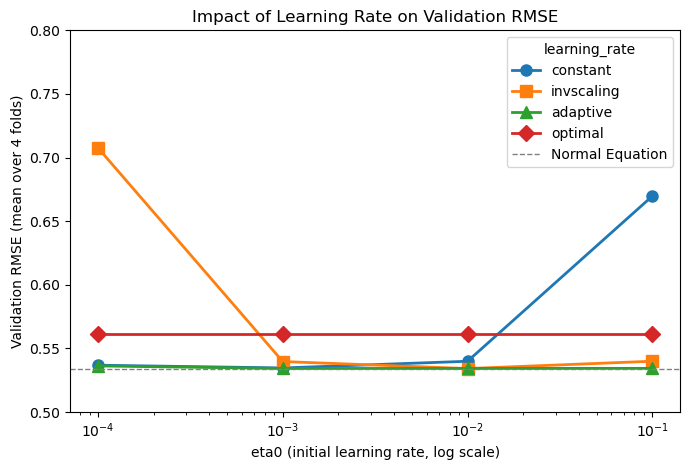

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for learning_rate, marker in zip(LEARNING_RATES, ['o', 's', '^', 'D']):
	rows = lr_table[lr_table['learning_rate'] == learning_rate]
	ax.plot(rows['eta0'], rows['val RMSE'], marker=marker, markersize=8, lw=2, label=learning_rate)
normal_equation_rmse = next(r['val RMSE'] for r in results if r['model'] == 'Normal Equation')
ax.axhline(normal_equation_rmse, color='gray', ls='--', lw=1, label='Normal Equation')
ax.set_xscale('log')
ax.set_ylim(0.5, 0.8)  # constant eta0=0.1 diverges far above this range
ax.set_xlabel('eta0 (initial learning rate, log scale)')
ax.set_ylabel('Validation RMSE (mean over 4 folds)')
ax.set_title('Impact of Learning Rate on Validation RMSE')
ax.legend(title='learning_rate')
plt.tight_layout()
plt.show()

Epochs used before the stopping rule kicked in, for each setting (fit on the full training set):

In [19]:
epochs_used = {}
for name in lr_names:
	with warnings.catch_warnings():
		warnings.simplefilter('ignore')
		fitted = clone(models[name]).fit(X, y)
	epochs_used[name] = fitted['model'].n_iter_

lr_table.assign(epochs=lr_table['model'].map(epochs_used)).pivot(index='learning_rate', columns='eta0', values='epochs').loc[LEARNING_RATES]

eta0,0.0001,0.0010,0.0100,0.1000
learning_rate,,,,
constant,33,9,8,10
invscaling,339,34,8,8
adaptive,48,34,41,54
optimal,49,49,49,49


#### Notes / Observations
- **Too small a learning rate underfits within the epoch budget.** `invscaling` with `eta0 = 0.0001` is the worst setting (RMSE 0.708): its step starts tiny and keeps shrinking, so after 339 epochs the weights have still not reached the minimum.
- **Too large a learning rate never settles.** `constant` with `eta0 = 0.1` jumps around the minimum (RMSE 0.670, training RMSE even higher at 0.680). `constant` with `eta0 = 0.01` is closer but still plateaus at 0.540, because a fixed step keeps bouncing the weights by roughly one step's worth of noise.
- **Schedules that shrink the step fix that.** `invscaling` with `eta0 = 0.01` (the default) and `adaptive` with `eta0 = 0.001` to `0.1` all reach about 0.534, matching the closed form.
- **`adaptive` is the most forgiving:** within 0.0002 of the best for every `eta0` from 0.001 to 0.1, because it starts big and cuts the step by 5x whenever progress stalls. It needs more epochs (34 to 54) since it waits 5 epochs without improvement before each cut.
- **`optimal` ignores `eta0`** (identical 0.561 in every column) and its alpha based step is poorly tuned for this problem at alpha = 0.001.
- **Speed vs safety:** a well chosen step converges in 8 epochs; a cautious one (`constant`, `eta0 = 0.0001`) takes 33 epochs to land slightly worse (0.537). Since every run takes well under a second here, the robustness of `adaptive` matters more than its extra epochs.

## Elastic Net Mixing (`l1_ratio`)

`l1_ratio` slides Elastic Net between Ridge (`0`) and Lasso (`1`). It is tested at `alpha = 0.1`, where QD.3 showed the penalty type actually matters (at `alpha = 0.001` every penalty behaves the same).

In [20]:
L1_RATIOS = [0.15, 0.85]  # 0.5 already ran in QD.3 as 'Elastic Net (alpha=0.1)'

l1_names = []
for l1_ratio in L1_RATIOS:
	name = f'Elastic Net (alpha=0.1, l1_ratio={l1_ratio})'
	evaluate(name, SGDRegressor(penalty='elasticnet', alpha=0.1, l1_ratio=l1_ratio, random_state=SEED),
			 method='SGD', penalty='elasticnet', alpha=0.1, l1_ratio=l1_ratio)
	l1_names.append(name)

mixing_names = ['Ridge (alpha=0.1)', l1_names[0], 'Elastic Net (alpha=0.1)', l1_names[1], 'Lasso (alpha=0.1)']
zero_weights = {name: int((clone(models[name]).fit(X, y)['model'].coef_ == 0).sum()) for name in mixing_names}

results_table(mixing_names).loc[mixing_names].assign(**{'# weights = 0': lambda d: d.index.map(zero_weights)})

,method,penalty,alpha,l1_ratio,train RMSE,val RMSE,val RMSE std,val MAE,val R2,# weights = 0
model,,,,,,,,,,
Ridge (alpha=0.1),SGD,l2,0.1,NaN,0.5334,0.5356,0.0300,0.4167,0.7664,0
"Elastic Net (alpha=0.1, l1_ratio=0.15)",SGD,elasticnet,0.1,0.15,0.5342,0.5363,0.0301,0.4179,0.7658,1
Elastic Net (alpha=0.1),SGD,elasticnet,0.1,0.50,0.5382,0.5407,0.0305,0.4228,0.7619,1
"Elastic Net (alpha=0.1, l1_ratio=0.85)",SGD,elasticnet,0.1,0.85,0.5472,0.5499,0.0284,0.4324,0.7539,1
Lasso (alpha=0.1),SGD,l1,0.1,NaN,0.5503,0.5531,0.0284,0.4353,0.7510,2


#### Notes / Observations
- `l1_ratio` behaves as a slider between the two pure penalties. At alpha = 0.1, validation RMSE climbs steadily from Ridge (0.5356) through `l1_ratio` 0.15 (0.5363), 0.5 (0.5407) and 0.85 (0.5499) to Lasso (0.5531).
- The more L1 in the mix, the more the weakest weights are pushed to 0. Every Elastic Net setting zeroes Negative affect, while pure Lasso also zeroes Generosity.
- Since this model is not overfitting, **less L1 is better** here. Elastic Net would earn its keep with many weak or redundant features, where its sparsity helps more than the extra bias hurts.

# QD.5 Select the Best Regularized Model

Every regularized SGD model trained above (QD.3 and QD.4) is a candidate. The winner is the one with the lowest mean validation RMSE.

In [21]:
candidates = pd.DataFrame([r for r in results if r['model'] in regularized_names + lr_names + l1_names]).set_index('model')
candidates = candidates.sort_values('val RMSE')

best_name = candidates.index[0]
best_params = models[best_name]['model'].get_params()
print(f'Selected: {best_name}')
print({k: best_params[k] for k in ['penalty', 'alpha', 'l1_ratio', 'learning_rate', 'eta0', 'power_t', 'max_iter', 'tol', 'random_state']})

candidates.drop(columns='method').head(10).round(4)

Selected: Ridge (alpha=0.001)
{'penalty': 'l2', 'alpha': 0.001, 'l1_ratio': 0.5, 'learning_rate': 'invscaling', 'eta0': 0.01, 'power_t': 0.25, 'max_iter': 1000, 'tol': 0.001, 'random_state': 42}


,penalty,alpha,l1_ratio,train RMSE,val RMSE,val RMSE std,val MAE,val R2,learning_rate,eta0
model,,,,,,,,,,
Ridge (alpha=0.001),l2,0.001,NaN,0.5318,0.5342,0.0307,0.4153,0.7675,NaN,NaN
"l2 alpha=0.001, invscaling eta0=0.01",l2,0.001,NaN,0.5318,0.5342,0.0307,0.4153,0.7675,invscaling,0.010
Elastic Net (alpha=0.001),elasticnet,0.001,0.50,0.5318,0.5342,0.0307,0.4153,0.7675,NaN,NaN
Lasso (alpha=0.001),l1,0.001,NaN,0.5318,0.5342,0.0307,0.4153,0.7675,NaN,NaN
"l2 alpha=0.001, adaptive eta0=0.001",l2,0.001,NaN,0.5316,0.5343,0.0305,0.4152,0.7675,adaptive,0.001
"l2 alpha=0.001, adaptive eta0=0.01",l2,0.001,NaN,0.5316,0.5343,0.0307,0.4151,0.7674,adaptive,0.010
"l2 alpha=0.001, adaptive eta0=0.1",l2,0.001,NaN,0.5316,0.5344,0.0307,0.4152,0.7674,adaptive,0.100
"l2 alpha=0.001, constant eta0=0.001",l2,0.001,NaN,0.5318,0.5347,0.0301,0.4155,0.7671,constant,0.001
Ridge (alpha=0.1),l2,0.100,NaN,0.5334,0.5356,0.0300,0.4167,0.7664,NaN,NaN


#### Notes / Observations
- **Selected: Ridge (L2), alpha = 0.001, `learning_rate = 'invscaling'`, `eta0 = 0.01`** (the scikit-learn defaults for everything except penalty and alpha), with validation RMSE 0.5342 ± 0.0307 and R² 0.7675.
- **This is effectively a tie.** Ridge, Lasso and Elastic Net at alpha = 0.001 differ by less than 0.00002 RMSE (0.534238 vs 0.534239 vs 0.534248), about 1,000 times smaller than the fold to fold standard deviation (0.031). Any of them, or the unregularized model, would perform the same on new data.
- Ridge is a sensible pick for the tie: it keeps every feature (QB and QC found that each one carries some signal) and its L2 penalty is the standard fix for the moderate GDP / Life expectancy overlap, keeping those two weights stable without changing the predictions.
- The selected model is no better than the closed-form solution (0.5343). The best penalty is the weakest one tried, which is consistent with a model that has no overfitting to correct.

# QD.6 Training and Validation Loss by Epoch (Selected Model)

To track the loss epoch by epoch, the selected model is rebuilt with `max_iter=1` and `warm_start=True`, then `fit` is called in a loop. Each call runs exactly one epoch and continues from the previous weights; after each call the Train and Validation RMSE are recorded.

To get a validation curve that does not depend on one lucky split, this is done on **each of the 4 CV folds** (train on 3, validate on the 4th) and the curves are averaged. `tol=None` turns off early stopping so every run goes the full 50 epochs.

> **Note:** each call to `fit` resets scikit-learn's internal update counter `t_`. For `invscaling` that means the step size jumps back up to `eta0` at the start of every epoch instead of continuing to shrink, so the loop is a close (not exact) replay of a single long `fit`. For `constant` the loop is exact.

In [22]:
N_EPOCHS = 50


def rmse(y_true, y_pred):
	return np.sqrt(mean_squared_error(y_true, y_pred))


train_curves, val_curves = [], []
for train_idx, val_idx in cv.split(X):
	pre = make_preprocessor().fit(X.iloc[train_idx])
	X_tr, X_val = pre.transform(X.iloc[train_idx]), pre.transform(X.iloc[val_idx])
	y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

	sgd = clone(models[best_name]['model']).set_params(max_iter=1, warm_start=True, tol=None)
	train_rmse, val_rmse = [], []
	for epoch in range(N_EPOCHS):
		with warnings.catch_warnings():
			warnings.simplefilter('ignore')  # ConvergenceWarning: expected, since max_iter=1
			sgd.fit(X_tr, y_tr)
		train_rmse.append(rmse(y_tr, sgd.predict(X_tr)))
		val_rmse.append(rmse(y_val, sgd.predict(X_val)))
	train_curves.append(train_rmse)
	val_curves.append(val_rmse)

train_curves, val_curves = np.array(train_curves), np.array(val_curves)
epoch_df = pd.DataFrame({
	'epoch': np.arange(1, N_EPOCHS + 1),
	'train RMSE': train_curves.mean(axis=0),
	'val RMSE': val_curves.mean(axis=0),
	'val RMSE std': val_curves.std(axis=0),
}).set_index('epoch')

epoch_df.loc[[1, 2, 3, 5, 10, 20, 30, 40, 50]].round(4)

,train RMSE,val RMSE,val RMSE std
epoch,,,
1,0.6525,0.6549,0.0214
2,0.5337,0.5367,0.0280
3,0.5326,0.5355,0.0296
5,0.5324,0.5350,0.0300
10,0.5323,0.5349,0.0301
20,0.5323,0.5349,0.0302
30,0.5323,0.5349,0.0302
40,0.5323,0.5349,0.0302
50,0.5323,0.5349,0.0302


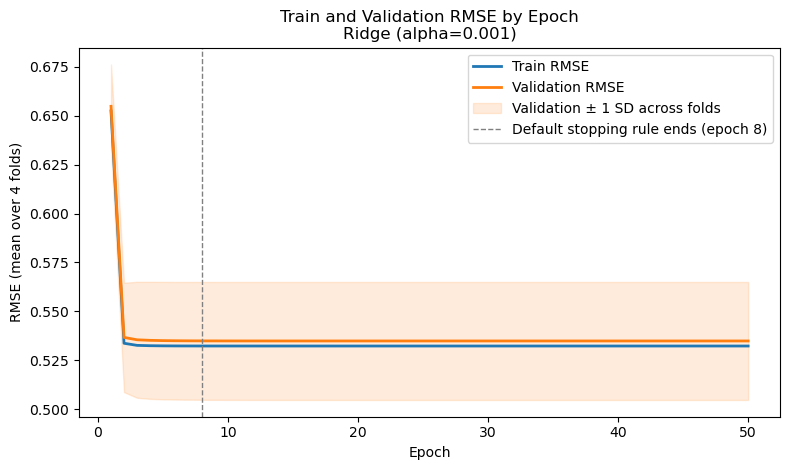

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(epoch_df.index, epoch_df['train RMSE'], lw=2, label='Train RMSE')
ax.plot(epoch_df.index, epoch_df['val RMSE'], lw=2, label='Validation RMSE')
ax.fill_between(epoch_df.index, epoch_df['val RMSE'] - epoch_df['val RMSE std'], epoch_df['val RMSE'] + epoch_df['val RMSE std'],
				color='tab:orange', alpha=0.15, label='Validation ± 1 SD across folds')

default_epochs = clone(models[best_name]).fit(X, y)['model'].n_iter_
ax.axvline(default_epochs, color='gray', ls='--', lw=1, label=f'Default stopping rule ends (epoch {default_epochs})')
ax.set_xlabel('Epoch')
ax.set_ylabel('RMSE (mean over 4 folds)')
ax.set_title(f'Train and Validation RMSE by Epoch\n{best_name}')
ax.legend()
plt.tight_layout()
plt.show()

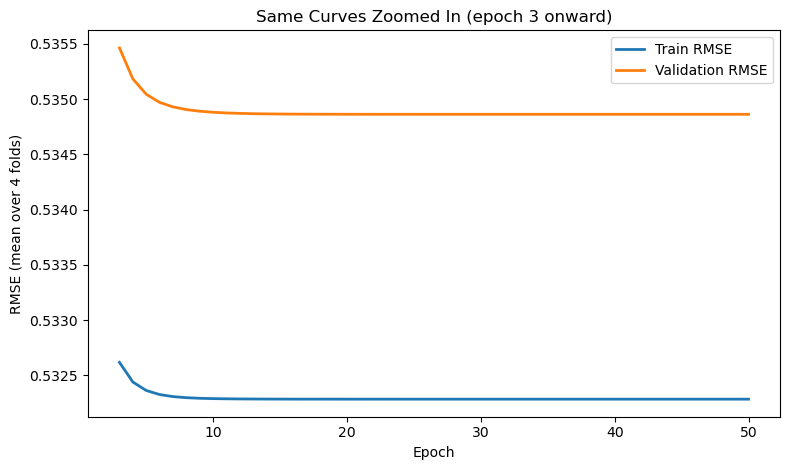

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.8))
zoom = epoch_df.loc[3:]
ax.plot(zoom.index, zoom['train RMSE'], lw=2, label='Train RMSE')
ax.plot(zoom.index, zoom['val RMSE'], lw=2, label='Validation RMSE')
ax.set_xlabel('Epoch')
ax.set_ylabel('RMSE (mean over 4 folds)')
ax.set_title('Same Curves Zoomed In (epoch 3 onward)')
ax.legend()
plt.tight_layout()
plt.show()

#### Notes / Observations
- **SGD converges almost immediately.** After 1 epoch the validation RMSE is 0.655. By epoch 2 it is 0.537 and by epoch 5 it is 0.535. From epoch 10 to 50 it does not change at the 4th decimal (0.5349).
- **The two curves run parallel with a tiny gap** (train 0.532 vs validation 0.535 at epoch 50), and the validation curve never turns back up. Training longer causes **no overfitting**, so early stopping is not needed for accuracy here, only to save time. The default stopping rule ends training after 8 epochs, which is right where the curves flatten.
- The validation band (±1 SD across folds, about ±0.03) is roughly 10 times wider than the train / validation gap. Which rows land in the validation fold matters more than how long the model trains.
- The loop's plateau (0.5349) is very slightly above the 0.5342 from the regular `fit` in QD.5. That is the `t_` reset described above: the step size restarts at `eta0` each epoch, so the weights keep a little more noise than in a single uninterrupted `fit`.

# QD.7 Train the Selected Model on the Entire Training Set

The selected pipeline (preprocessing + SGD with the chosen hyperparameters) is refit on all 1,559 training rows. Its default stopping rule (`tol = 0.001`) decides the number of epochs, which QD.6 shows is past the point where the validation loss levels off. The test set is still untouched.

In [25]:
final_model = clone(models[best_name]).fit(X, y)
final_sgd = final_model['model']

print(f'Final model: {best_name}')
print(f'Epochs run: {final_sgd.n_iter_}')
print(f'Training RMSE (entire training set): {rmse(y, final_model.predict(X)):.4f}')
print(f"Expected RMSE on unseen data (4-fold CV): {candidates.loc[best_name, 'val RMSE']:.4f} ± {candidates.loc[best_name, 'val RMSE std']:.4f}")

Final model: Ridge (alpha=0.001)
Epochs run: 8
Training RMSE (entire training set): 0.5322
Expected RMSE on unseen data (4-fold CV): 0.5342 ± 0.0307


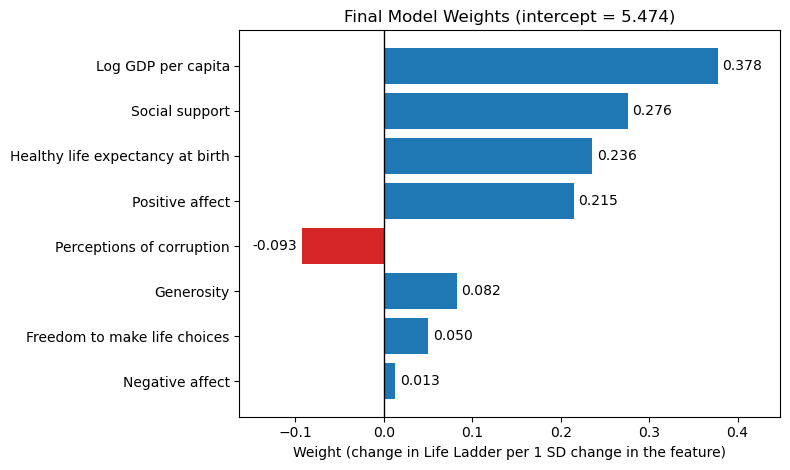

In [26]:
final_weights = pd.Series(final_sgd.coef_, index=final_model['pre'].get_feature_names_out(), name='weight')

fig, ax = plt.subplots(figsize=(8, 4.8))
final_weights = final_weights.sort_values(key=abs)
ax.barh(final_weights.index, final_weights, color=['tab:blue' if w > 0 else 'tab:red' for w in final_weights])
for i, w in enumerate(final_weights):
	ax.text(w + (0.005 if w >= 0 else -0.005), i, f'{w:.3f}', va='center', ha='left' if w >= 0 else 'right')
ax.axvline(0, color='black', lw=1)
ax.margins(x=0.15)  # room for the value labels
ax.set_xlabel(f'Weight (change in {TARGET} per 1 SD change in the feature)')
ax.set_title(f'Final Model Weights (intercept = {final_sgd.intercept_[0]:.3f})')
plt.tight_layout()
plt.show()

#### Notes / Observations
- The final model trains in **8 epochs**, with **training RMSE 0.532** on the full training set. Its expected error on new data, from cross-validation, is **0.534 ± 0.031** Life Ladder points (R² about 0.77).
- **Weights:** Log GDP (0.38) is the strongest driver, followed by Social support (0.28), Life expectancy (0.24) and Positive affect (0.22). Corruption is the only clearly negative weight (-0.09). Negative affect contributes almost nothing (0.01) once the other features are known, matching QC's finding that it adds little.
- The intercept (5.47) is the predicted happiness for a country with every feature at its training average. Because the features are standardized, it lands almost exactly on the mean Life Ladder score (5.47).
- `final_model` is a full pipeline, so it can be applied directly to the raw test set (`final_model.predict(test_X)`) with the same imputation, transforms and scaling learned from the training data. It is saved below as `MODELS/linear_regression_model.joblib` for QF.

## Save the Final Model for QF

The fitted pipeline is written to disk so the main notebook (QF) can load it and predict on the test set without retraining. The file also records the model name and its cross-validation scores, so QF can compare the test RMSE against what cross-validation expected. Nothing in this appendix reads the test set.

In [27]:
import os
import joblib

model_path = '/Q1_OLD/MODELS/linear_regression_model.joblib'
os.makedirs(os.path.dirname(model_path), exist_ok=True)

joblib.dump({
	'name': best_name,
	'model': final_model,
	'train RMSE': rmse(y, final_model.predict(X)),
	'val RMSE': candidates.loc[best_name, 'val RMSE'],
	'val RMSE std': candidates.loc[best_name, 'val RMSE std'],
	'source': 'Appendix B, QD.7',
}, model_path)

print(f'Saved {best_name} to {model_path}')

Saved Ridge (alpha=0.001) to /Users/mrt/Documents/MrT/IUBloomington/Fall 2026 - Applied Machine Learning/code/hw/Applied-ML-HW1/Q1/MODELS/linear_regression_model.joblib


# Summary of All Models

In [28]:
pd.DataFrame(results).set_index('model').drop(columns='method').sort_values('val RMSE').round(4)

,train RMSE,val RMSE,val RMSE std,val MAE,val R2,penalty,alpha,l1_ratio,learning_rate,eta0
model,,,,,,,,,,
"l2 alpha=0.001, invscaling eta0=0.01",0.5318,0.5342,0.0307,0.4153,0.7675,l2,0.001,NaN,invscaling,0.0100
Ridge (alpha=0.001),0.5318,0.5342,0.0307,0.4153,0.7675,l2,0.001,NaN,NaN,NaN
SGD (no penalty),0.5318,0.5342,0.0307,0.4153,0.7675,none,NaN,NaN,NaN,NaN
Elastic Net (alpha=0.001),0.5318,0.5342,0.0307,0.4153,0.7675,elasticnet,0.001,0.50,NaN,NaN
Lasso (alpha=0.001),0.5318,0.5342,0.0307,0.4153,0.7675,l1,0.001,NaN,NaN,NaN
Normal Equation,0.5316,0.5343,0.0307,0.4151,0.7675,NaN,NaN,NaN,NaN,NaN
LinearRegression (SVD),0.5316,0.5343,0.0307,0.4151,0.7675,NaN,NaN,NaN,NaN,NaN
"l2 alpha=0.001, adaptive eta0=0.001",0.5316,0.5343,0.0305,0.4152,0.7675,l2,0.001,NaN,adaptive,0.0010
"l2 alpha=0.001, adaptive eta0=0.01",0.5316,0.5343,0.0307,0.4151,0.7674,l2,0.001,NaN,adaptive,0.0100
